Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 43.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.19MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.39MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.79MB/s]


Epoch [1/3] D Loss: 0.2822 G Loss: 2.0340
Epoch [2/3] D Loss: 0.4263 G Loss: 1.4254
Epoch [3/3] D Loss: 0.4156 G Loss: 1.2888


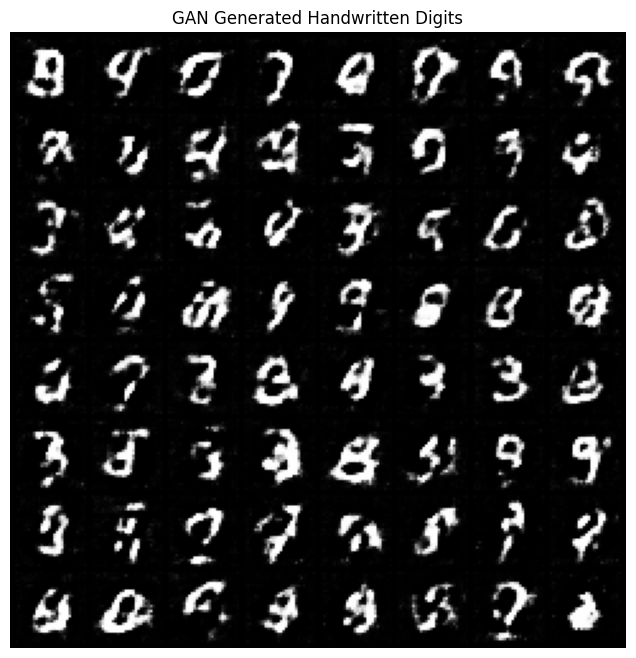

Generated images saved successfully.
Output file: generated_digits.png


In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

latent_dim = 64
batch_size = 128
epochs = 3
learning_rate = 0.0002

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

dataset = Subset(dataset, range(10000))
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, img):
        return self.net(img)


G = Generator().to(device)
D = Discriminator().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    G.parameters(), lr=learning_rate, betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    D.parameters(), lr=learning_rate, betas=(0.5, 0.999)
)

fixed_noise = torch.randn(64, latent_dim, 1, 1, device=device)

for epoch in range(epochs):
    G.train()
    D.train()

    total_g_loss = 0
    total_d_loss = 0

    for real_images, _ in loader:
        real_images = real_images.to(device)
        current_batch = real_images.size(0)

        real_labels = torch.ones(current_batch, 1, device=device)
        fake_labels = torch.zeros(current_batch, 1, device=device)

        noise = torch.randn(
            current_batch, latent_dim, 1, 1, device=device
        )

        fake_images = G(noise)

        real_output = D(real_images)
        fake_output = D(fake_images.detach())

        loss_real = criterion(real_output, real_labels)
        loss_fake = criterion(fake_output, fake_labels)
        loss_D = (loss_real + loss_fake) / 2

        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        output = D(fake_images)
        loss_G = criterion(output, real_labels)

        optimizer_G.zero_grad()
        loss_G.backward()
        optimizer_G.step()

        total_d_loss += loss_D.item()
        total_g_loss += loss_G.item()

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"D Loss: {total_d_loss / len(loader):.4f} "
        f"G Loss: {total_g_loss / len(loader):.4f}"
    )

    G.eval()
    with torch.no_grad():
        generated = G(fixed_noise).cpu()

    torchvision.utils.save_image(
        generated,
        f"generated_epoch_{epoch + 1}.png",
        nrow=8,
        normalize=True,
        value_range=(-1, 1)
    )

G.eval()

with torch.no_grad():
    generated = G(fixed_noise).cpu()

torchvision.utils.save_image(
    generated,
    "generated_digits.png",
    nrow=8,
    normalize=True,
    value_range=(-1, 1)
)

real_images, _ = next(iter(loader))

torchvision.utils.save_image(
    real_images[:64],
    "real_digits.png",
    nrow=8,
    normalize=True,
    value_range=(-1, 1)
)

grid = torchvision.utils.make_grid(
    generated, nrow=8, normalize=True, value_range=(-1, 1)
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("GAN Generated Handwritten Digits")
plt.axis("off")
plt.show()

print("Generated images saved successfully.")
print("Output file: generated_digits.png")